In [116]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [117]:
import os
from tqdm import tqdm

import torch
import numpy as np

import h5py

import matplotlib.pyplot as plt
from schnetpack import units as spk_units
from schnetpack import properties
from schnetpack.md.data import HDF5Loader
from imlff.common.util import proj_path
from imlff.data.info import md17_conformations_per_molecule, md22_conformations_per_molecule
from imlff.analysis.molecules import create_batch
import MDAnalysis as mda
from MDAnalysis.analysis.dihedrals import Dihedral

from imlff.data.info import molecule_to_n_atoms

from IPython.display import display, Image

from matplotlib.patches import Rectangle
import pandas as pd
from ase import Atoms
from ase.io import write
from pathlib import Path
from ase import units
import seaborn as sns
import matplotlib.pyplot as plt

## From wandb

In [ ]:

import pandas as pd
from imlff.analysis.base import fetch_runs_df


save_name = 'feb-16/md-Ala3'
overwrite = False

kwargs = {
    'molecule_config.molecule_name': 'Ac-Ala3-NHMe',
}
sims_df_full = fetch_runs_df(
    project_name='md-v7-test',
    max_runs=None,
    **kwargs,
    fix=False
)

for col in ['model_config', 'molecule_config', 'md_config', 'train']:
    sims_df_full = pd.concat([
        sims_df_full[col].apply(pd.Series).add_prefix(f"{col}__"),
        sims_df_full.drop([col], axis=1),
    ], axis=1)
sims_df_full['train__molecule'] = sims_df_full['train__molecule'].dropna().unique()[0]

for c in sims_df_full.columns:
    if 'train' in c: continue
    print(c)


sims_df_full['n_atoms'] = sims_df_full.train__molecule.apply(molecule_to_n_atoms)
sims_df_full = sims_df_full.sort_values(['n_atoms', '_step'], ascending=[True, False]).reset_index(drop=True)
sims_df_full.groupby(['train__AtomisticRepresentationClass', 'train__molecule'])[['_step']].agg([['count', 'min', 'max', 'median']])

## Ramachandran Plot

In [ ]:
row = sims_df_full.query('run_id=="wxrahzwj"').iloc[0]
log_path = row.proj_path
angle_path = f"{log_path}_angles.npz"
dat = np.load(angle_path)
phi_angles, psi_angles = dat['phi'], dat['psi']
phi_angles.shape

(2000000,)

In [14]:
from matplotlib.lines import Line2D
import seaborn as sns

def joint_overlay(
    x1, y1, x2, y2,
    kind_1d="kde",          # "kde" or "hist"
    bins=50,
    cmap="Greens",
    color_1d="green",
    color_ref="black",
    fill_1d=False,         # NEW: fill non-ref 1D KDE
    lw_1d=1.0,             # NEW: line width for 1D plots
    alpha_1d=0.4,           # NEW: fill alpha for 1D KDE
    marg_ratio = 0.6,
    annotation = '',
    box_bl=(0, -150),     # bottom-left (x0, y0)
    box_tr=(150, 150),   # top-right (x1, y1)
    
    legend=True,
):

    import matplotlib.pyplot as plt
    import seaborn as sns

    fig = plt.figure(figsize=(6, 6))
    gs = fig.add_gridspec(
        2, 2,
        width_ratios=(4, marg_ratio),
        height_ratios=(marg_ratio, 4),
        wspace=0.05,
        hspace=0.05,
    )

    ax_joint = fig.add_subplot(gs[1, 0])
    ax_marg_x = fig.add_subplot(gs[0, 0], sharex=ax_joint)
    ax_marg_y = fig.add_subplot(gs[1, 1], sharey=ax_joint)

    # --- joint ---
    sns.kdeplot(x=x1, y=y1, ax=ax_joint,
                fill=True, cmap=cmap, thresh=1e-4)
    sns.kdeplot(x=x2, y=y2, ax=ax_joint,
                color=color_ref, levels=8, linewidths=1)

    # --- marginals ---
    if kind_1d == "kde":
        if fill_1d:
            sns.kdeplot(
                x=x1, ax=ax_marg_x,
                fill=True, color=color_1d,
                alpha=alpha_1d, linewidth=0
            )
            sns.kdeplot(
                y=y1, ax=ax_marg_y,
                fill=True, color=color_1d,
                alpha=alpha_1d, linewidth=0
            )
        else:
            sns.kdeplot(
                x=x1, ax=ax_marg_x,
                color=color_1d, linewidth=lw_1d
            )
            sns.kdeplot(
                y=y1, ax=ax_marg_y,
                color=color_1d, linewidth=lw_1d
            )

        # reference: always line-only
        sns.kdeplot(
            x=x2, ax=ax_marg_x,
            color=color_ref, linewidth=lw_1d
        )
        sns.kdeplot(
            y=y2, ax=ax_marg_y,
            color=color_ref, linewidth=lw_1d
        )

    else:
        ax_marg_x.hist(x1, bins=bins, density=True,
                       color=color_1d, alpha=0.5)
        ax_marg_x.hist(x2, bins=bins, density=True,
                       histtype="step", color=color_ref)

        ax_marg_y.hist(y1, bins=bins, density=True,
                       orientation="horizontal",
                       color=color_1d, alpha=0.5)
        ax_marg_y.hist(y2, bins=bins, density=True,
                       orientation="horizontal",
                       histtype="step", color=color_ref)

    # --- cosmetics ---
    for ax in (ax_marg_x, ax_marg_y):
        ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

    ax_joint.set_xlim(-180, 180)
    ax_joint.set_ylim(-180, 180)
    ax_joint.set_xlabel("$\phi$")
    ax_joint.set_ylabel("$\psi$")
    
    
    # dashed reference box
        
    x0, y0 = box_bl
    x1, y1 = box_tr

    # dashed reference box
    rect = Rectangle(
        (x0, y0),
        x1 - x0,
        y1 - y0,
        fill=False,
        edgecolor=color_ref,
        linestyle="--",
        linewidth=1.5,
    )
    ax_joint.add_patch(rect)

    if annotation:
        ax_joint.text(
            x0 + 0.02 * (x1 - x0),
            y1 - 0.02 * (y1 - y0),
            annotation,
            color=color_ref,
            fontsize=9,
            ha="left",
            va="top",
        )
        
    if legend:
        mild_green = sns.color_palette(cmap, 3)[1]  # second color for mild green

        # custom legend lines
        legend_lines = [
            Line2D([0], [0], color=mild_green, lw=2, label="Implicit FF distribution"),
            Line2D([0], [0], color=color_ref, lw=2, label="Reference distribution"),
        ]

        # place legend in upper marginal x axis (top-right)
        ax_marg_x.legend(
            handles=legend_lines,
            loc="upper right",
            frameon=False,
            fontsize=9
        )

    return fig, ax_joint

/tmp/ipykernel_2089971/2447974246.py:23: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


~/imlff/../imlff-paper/figures/ramachandran_plot/joint.pdf


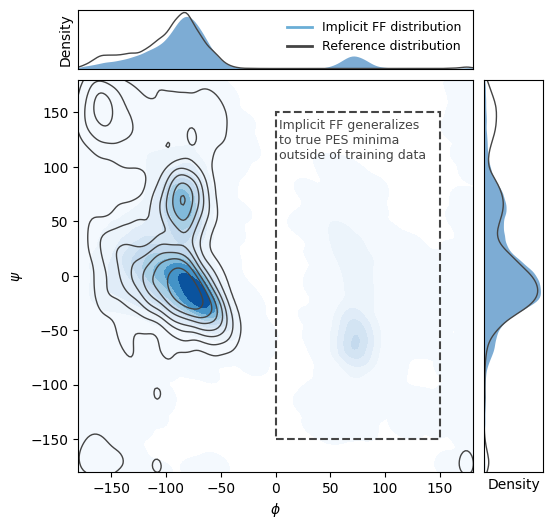

In [15]:
fast = False

fig, ax_joint = joint_overlay(
    phi_angles[::1000**fast],
    psi_angles[::1000**fast],
    
    phi_angles_ref[::100**fast],
    psi_angles_ref[::100**fast],
    
    kind_1d="kde",  # or "hist"
    color_ref="#444444",
    
    cmap='Blues',
    color_1d=sns.color_palette('Blues', 10)[7],
    alpha_1d=0.6,
    
    lw_1d=1.0,
    fill_1d = True,
    
    # annotation = "No training data,\nImplicit FF generalizes,\nfinds another true minima",
    annotation = "Implicit FF generalizes\nto true PES minima\noutside of training data",
)
plt.tight_layout()
if not fast:
    plot_path = '../imlff-paper/figures/ramachandran_plot'
    filename = 'joint'
    pat = proj_path(f'{plot_path}/{filename}.pdf')
    print(pat)
    fig.savefig(pat, bbox_inches="tight")
plt.show()

### Plot iter count of cold rerun

In [178]:
row_rerun = sims_df_full.query('run_id=="j9ohxjhn"').iloc[0]
rerun_path = f"{row_rerun.proj_path}_rerun.h5"
row_rerun = sims_df_full.query('run_id=="wxrahzwj"').iloc[0]
rerun_path = f"{row_rerun.proj_path}_rerun_every2_mi20.h5"

with h5py.File(rerun_path, "r", swmr=True) as f:
    f.visititems(lambda name, obj: print(name, obj.shape) if hasattr(obj, "shape") else None)

back_res (1000000, 42, 20)
forw_res (1000000, 42, 20)


In [129]:
from imlff.md.util import get_atoms
from imlff.data.info import molecule_to_n_conformations, molecule_to_dataset


In [149]:
try:
    energy_ref_path = proj_path('data/MD22/Ac-Ala3-NHMe__energy.npy')
    energy_ref = np.load(energy_ref_path)
except:
    mol = 'Ac-Ala3-NHMe'
    atoms_list = [get_atoms(mol, i+1) for i in tqdm(range(molecule_to_n_conformations(mol)))]
    energy_ref = np.array([a.info['energy'] for a in atoms_list])
    energy_ref_path_non_tmp = proj_path('data/MD22/Ac-Ala3-NHMe__energy', use_tmp=False)
    np.save(energy_ref_path_non_tmp, energy_ref)

Starting copy from 
~/imlff/data/MD22/Ac-Ala3-NHMe__energy.npy 
to 
/temp-in-container/imlff/data/MD22/Ac-Ala3-NHMe__energy.npy
Copied file: ~/imlff/data/MD22/Ac-Ala3-NHMe__energy.npy -> /temp-in-container/imlff/data/MD22/Ac-Ala3-NHMe__energy.npy


Text(0, 0.5, 'count (red)')

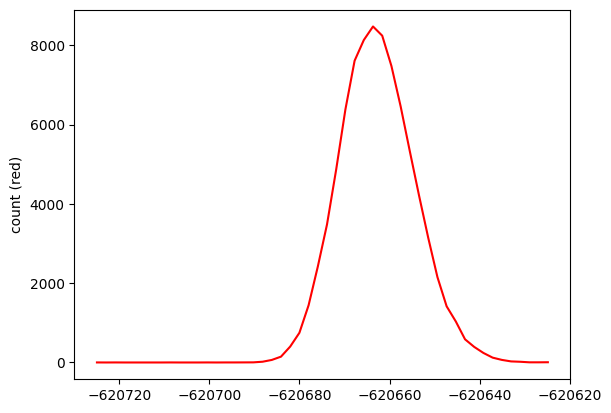

In [152]:
from scipy.stats import binned_statistic

bins=50
# bins=40

count, edges, _ = binned_statistic(energy_ref, energy_ref, statistic='count', bins=bins)
centers = (edges[:-1] + edges[1:]) / 2
plt.plot(centers, count, color='red')
plt.ylabel('count (red)')

In [15]:
# with h5py.File(rerun_path, 'r', swmr=True) as f:
#     # forw_res/back_res: (n_steps, n_atoms, max_iter), NaN-padded
#     # iteration count per step = number of non-NaN iterations (mean over atoms)
#     forw_res = f['forw_res'][:]  # (n_steps, n_atoms, max_iter)
#     back_res = f['back_res'][:]
# forw_res.shape

In [179]:
from imlff.scripts.compute_dihedral_angles import (
    precompute_rerun_iters, get_n_rerun
)
import numpy as np

n_rerun = 1_000_000
forw_threshold = 0.01
forw_cache, back_cache, n_rerun = precompute_rerun_iters(
    rerun_path, forw_threshold=forw_threshold, n_rerun=n_rerun,
)
forw_iters = np.load(forw_cache).astype(float)[:n_rerun]
back_iters = np.load(back_cache).astype(float)[:n_rerun]
print(f"n_rerun={n_rerun}, forw_iters={forw_iters.shape}, back_iters={back_iters.shape}")

  SKIP (exists): results/Ac-Ala3-NHMe_50000_fmax0.01000_stepsmax01000/solvF_tol0.001_mi10_bsolvF_btol0.0001_bmi10_warm_z1_g_bar1__painn_deq_i1_b512_rbf50_cut5_solvFNI_tol0.001_mi10__qcml-group_dev-v10_model-q55bhvpk:v19/03-25-b/MD__VV_T0400K_dt0.50fs_Langevin0320fs_rerun_every2_mi20.h5_forw_iters_n1000000_tol0.01.npy
  SKIP (exists): results/Ac-Ala3-NHMe_50000_fmax0.01000_stepsmax01000/solvF_tol0.001_mi10_bsolvF_btol0.0001_bmi10_warm_z1_g_bar1__painn_deq_i1_b512_rbf50_cut5_solvFNI_tol0.001_mi10__qcml-group_dev-v10_model-q55bhvpk:v19/03-25-b/MD__VV_T0400K_dt0.50fs_Langevin0320fs_rerun_every2_mi20.h5_back_iters_n1000000_tol0.01.npy
n_rerun=1000000, forw_iters=(1000000,), back_iters=(1000000,)


In [180]:
md_path = f"{row_rerun.proj_path}.hdf5"
assert os.path.exists(md_path)
    
with HDF5Loader(md_path, skip_initial=0) as data:
    energy_full = data.properties['energy'].flatten()
del data
energy_full.shape

INFO:schnetpack.md.data.hdf5_data:Loaded properties _atomic_numbers, masses, energy_system, _positions, velocities, _cell, energy, forces, forw_iterations and back_iterations from results/Ac-Ala3-NHMe_50000_fmax0.01000_stepsmax01000/solvF_tol0.001_mi10_bsolvF_btol0.0001_bmi10_warm_z1_g_bar1__painn_deq_i1_b512_rbf50_cut5_solvFNI_tol0.001_mi10__qcml-group_dev-v10_model-q55bhvpk:v19/03-25-b/MD__VV_T0400K_dt0.50fs_Langevin0320fs.hdf5


(2000000,)

In [ ]:
energy = energy_full[:n_rerun]
energy.shape

In [182]:
energy = energy_full[::2][:n_rerun]
energy.shape

(1000000,)

~/imlff/../imlff-paper/figures/energy_to_iterations/line_mean_distributions_b30.pdf


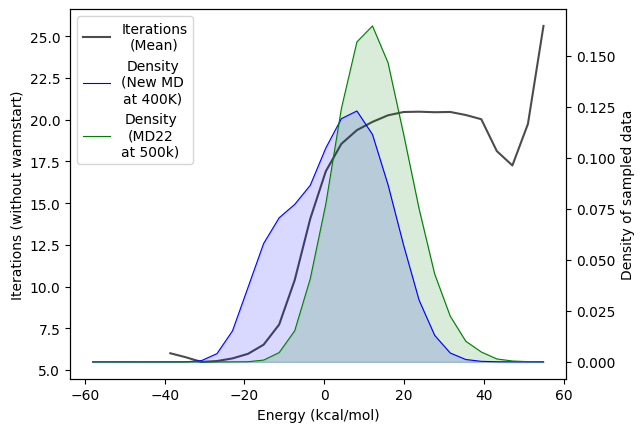

In [216]:
from scipy.stats import binned_statistic

bins = 50
dist = True
err = False

bins = 30
# dist = 'md'

save = True

ax = plt.gca()
ax.set_xlabel('Energy (kcal/mol)')
ax.set_ylabel('Iterations (without warmstart)')

for iters, label in [(forw_iters + back_iters, 'Iterations'),]:
    mean, edges, _ = binned_statistic(energy, iters, statistic='mean', bins=bins)
    std,  _,     _ = binned_statistic(energy, iters, statistic='std',  bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    
    kw = dict(alpha=0.7, color='black')
    
    if err:
        ax.errorbar(centers, mean, yerr=std, label=label+'\n(Mean,Std)', **kw)
    else:
        ax.plot(centers, mean, label=label+'\n(Mean)', **kw)
handles, labels = ax.get_legend_handles_labels()

if dist:
    ax = ax.twinx()
    ax.set_ylabel('Density of sampled data')

    def pl(count, color, label):
        normalized = count / count.sum()
        ax.plot(centers, normalized, color=color, linewidth=0.8, label=label)
        ax.fill_between(centers, normalized, alpha=0.15, color=color)

    if dist in [True, 'md']:
        count, _, _ = binned_statistic(energy, iters, statistic='count', bins=bins)
        pl(count=count, color='blue', label='Density\n(New MD\nat 400K)')

    if dist in [True, 'train']:
        count, _, _ = binned_statistic(energy_ref, energy_ref, statistic='count', bins=bins)
        pl(count=count, color='green', label='Density\n(MD22\nat 500k)')

    h2, l2 = ax.get_legend_handles_labels()
    handles += h2
    labels += l2
    
# Unified legend from both axes
leg = ax.legend(handles, labels, loc='upper left')
for text in leg.get_texts():
    text.set_ha('center')

if save:
    plot_path = '../imlff-paper/figures/energy_to_iterations'
    dist_str = {
        True: "_distributions",
        'md': '_md_distribution',
        'train': '_train_distribution',
        False: '',
    }[dist]
    filename = f'line_mean{"_std"*err}{dist_str}_b{bins}'
    pat = proj_path(f'{plot_path}/{filename}.pdf')
    print(pat)
    plt.savefig(pat, bbox_inches="tight")

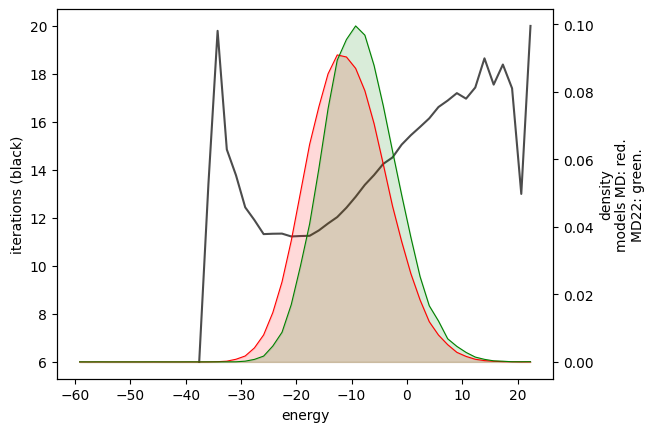

In [161]:
from scipy.stats import binned_statistic

bins=50
# bins=40

plt.xlabel('energy')
plt.ylabel('iterations (black)')
# plt.legend()

for iters, label in [
    # (forw_iters, 'forw'),
    # (back_iters, 'back'),
    (forw_iters+back_iters, 'both'),
    ]:
    mean, edges, _ = binned_statistic(energy, iters, statistic='mean', bins=bins)
    std,  _,     _ = binned_statistic(energy, iters, statistic='std',  bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    plt.errorbar(centers, mean, yerr=std*0, label=label, alpha=0.7, color='black')

if 1:
    count,  _,     _ = binned_statistic(energy, iters, statistic='count',  bins=bins)
    ax2 = plt.gca().twinx()
    def pl(count, color):
        ax2.plot(centers, count / count.sum(), color=color, linewidth=0.8)
        ax2.fill_between(centers, count / count.sum(), alpha=0.15, color=color)
    pl(count=count, color='red')
    ax2.set_ylabel('density (red)')

    count, _, _ = binned_statistic(energy_ref, energy_ref, statistic='count', bins=bins)
    pl(count=count, color='green')
    ax2.set_ylabel('density\nmodels MD: red.\nMD22: green.')

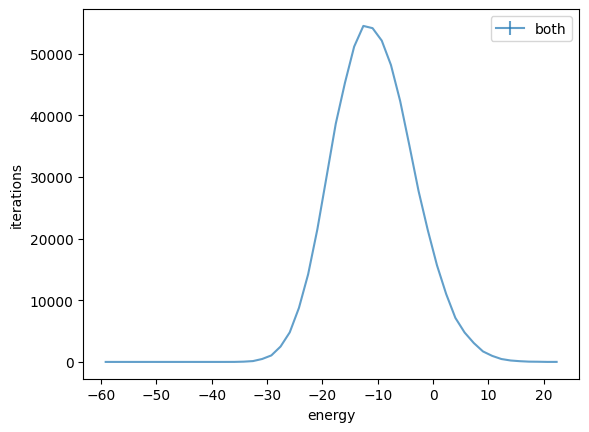

In [70]:
from scipy.stats import binned_statistic
for iters, label in [
    # (forw_iters, 'forw'),
    # (back_iters, 'back'),
    (forw_iters+back_iters, 'both'),
    ]:
    mean, edges, _ = binned_statistic(energy, iters, statistic='count',  bins=50)
    centers = (edges[:-1] + edges[1:]) / 2
    plt.errorbar(centers, mean, yerr=std*0, label=label, alpha=0.7)
plt.xlabel('energy'); plt.ylabel('iterations'); plt.legend()

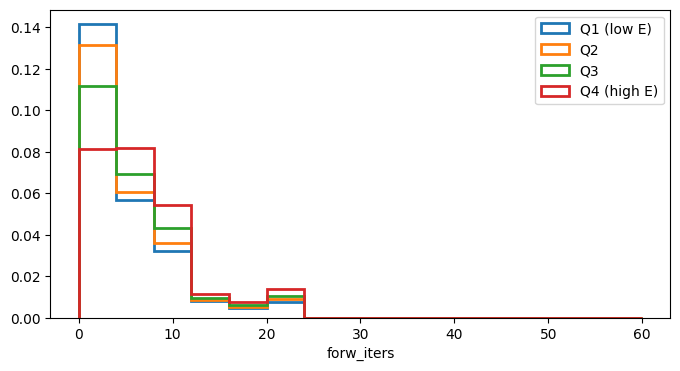

In [ ]:
quartiles = np.quantile(energy, [0, 0.25, 0.5, 0.75, 1.0])
labels = ['Q1 (low E)', 'Q2', 'Q3', 'Q4 (high E)']
n = 4
bins = range(0, 16 * n, n)

fig, ax = plt.subplots(figsize=(8, 4))
for i in range(4):
    mask = (energy >= quartiles[i]) & (energy < quartiles[i + 1])
    ax.hist(forw_iters[mask], bins=bins, density=True, label=labels[i],
            histtype='step', linewidth=2)
ax.set_xlabel('forw_iters')
ax.legend()

In [197]:
bins = list(range(2, 5))


def _iter_label(lo, hi, is_last):
    lo_i, hi_i = int(lo), int(hi)
    if is_last:
        return f'{lo_i}+'
    upper = hi_i if is_last else hi_i - 1
    return str(lo_i) if upper == lo_i else f'{lo_i}-{upper}'

tick_labels = [
    _iter_label(bins[j], bins[j+1], j == len(bins) - 2)
    for j in range(len(bins) - 1)
]
tick_labels

['2', '3+']

~/imlff/../imlff-paper/figures/energy_to_iterations/hist_n1.pdf
~/imlff/../imlff-paper/figures/energy_to_iterations/hist_n2.pdf
~/imlff/../imlff-paper/figures/energy_to_iterations/hist_n3.pdf
~/imlff/../imlff-paper/figures/energy_to_iterations/hist_n4.pdf
~/imlff/../imlff-paper/figures/energy_to_iterations/hist_n5.pdf
~/imlff/../imlff-paper/figures/energy_to_iterations/hist_n6.pdf


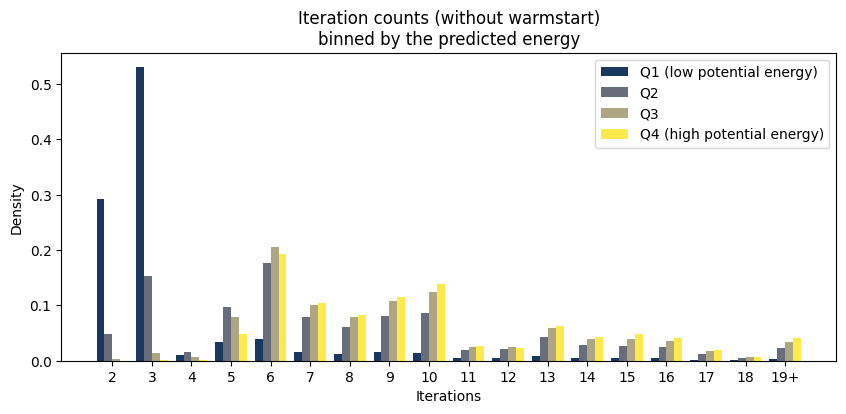

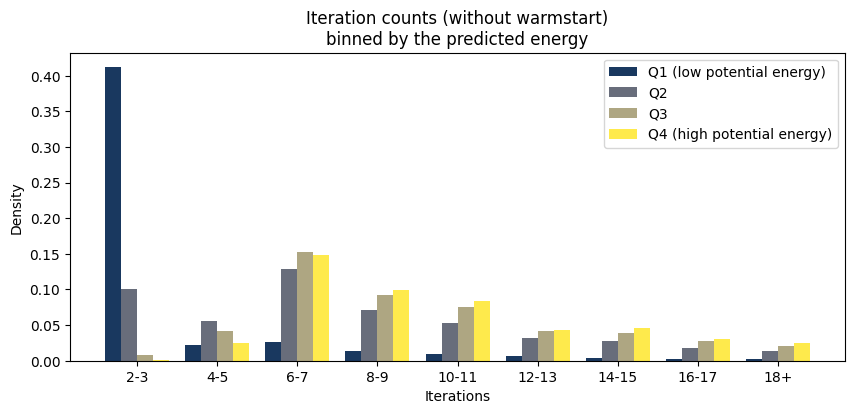

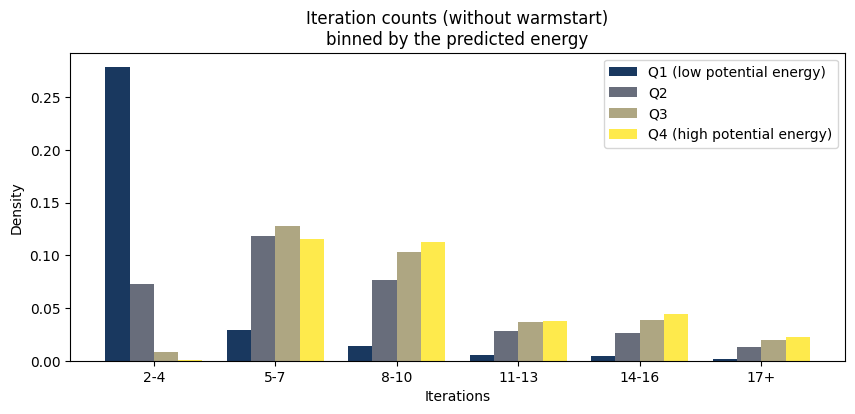

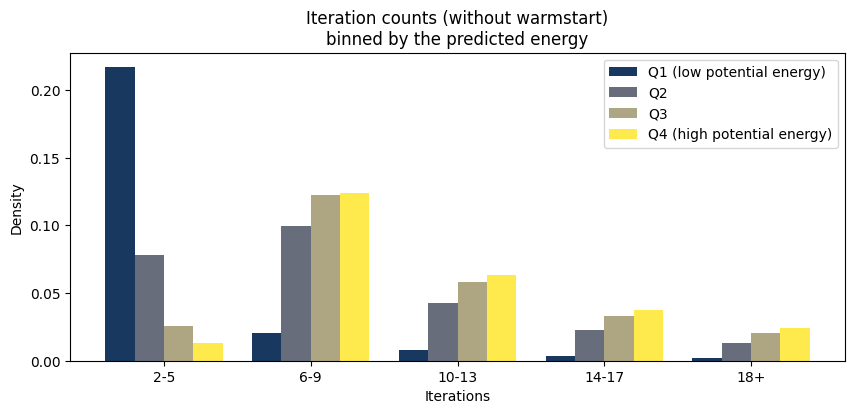

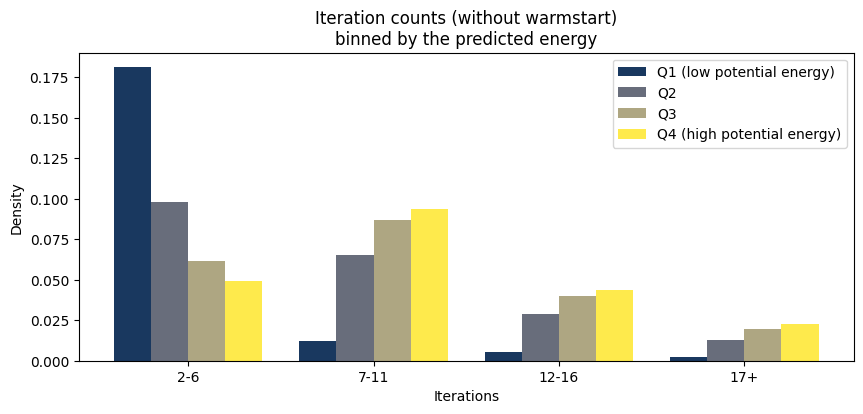

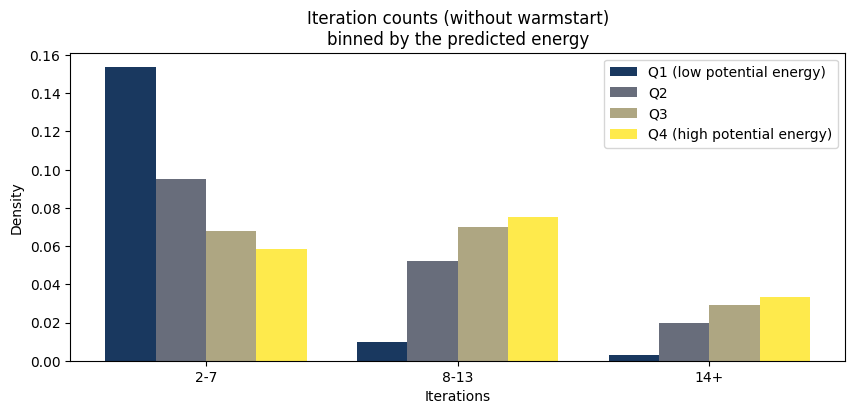

In [202]:
quartiles = np.quantile(energy, [0, 0.25, 0.5, 0.75, 1.0])
labels = ['Q1 (low potential energy)', 'Q2', 'Q3', 'Q4 (high potential energy)']

iters = forw_iters
iters_label = 'forw_iters'
iters = back_iters
iters_label = 'back_iters'
iters = (forw_iters + back_iters) / 2
iters_label = 'Iterations'

for n in range(1,7):
    lo_val = int(np.floor(iters.min()))
    hi_val = int(np.ceil(iters.max()))
    bins = np.unique(np.append(np.arange(lo_val, hi_val, n), hi_val))
    centers = bins[:-1] + n / 2
    bar_width = n / 5
    offsets = np.linspace(-1.5, 1.5, 4) * bar_width

    def _iter_label(lo, hi, is_last):
        lo_i, hi_i = int(lo), int(hi)
        if is_last:
            return f'{lo_i}+'
        upper = hi_i if is_last else hi_i - 1
        return str(lo_i) if upper == lo_i else f'{lo_i}-{upper}'

    tick_labels = [
        _iter_label(bins[j], bins[j+1], j == len(bins) - 2)
        for j in range(len(bins) - 1)
    ]

    # Green → Yellow → Red  (low=good, high=bad feel)
    cmap = plt.cm.RdYlGn_r

    # Blue → Yellow  (perceptually uniform, good for publications)
    cmap = plt.cm.cividis    # blue→olive-yellow, colorblind-safe
    # cmap = plt.cm.plasma     # purple-blue→bright yellow, high contrast

    # # Volcano / lava  (dark→red→orange→yellow→white)
    # cmap = plt.cm.hot        # black→red→orange→yellow→white
    # cmap = plt.cm.magma      # black→purple→red→peach (softer)
    # cmap = plt.cm.inferno_r    # black→purple→red→yellow (vivid)

    fig, ax = plt.subplots(figsize=(10, 4))
    for i in range(4):
        mask = (energy >= quartiles[i]) & (energy < quartiles[i + 1])
        counts, _ = np.histogram(iters[mask], bins=bins, density=True)
        ax.bar(centers + offsets[i], counts, width=bar_width, label=labels[i], alpha=0.9, color=cmap(i / 3))
        

    ax.set_xlabel(iters_label)
    ax.set_ylabel('Density')
    ax.set_xticks(centers)
    ax.set_xticklabels(tick_labels)
    ax.legend()
    ax.set_title('Iteration counts (without warmstart)\nbinned by the predicted energy')


    plot_path = '../imlff-paper/figures/energy_to_iterations'
    filename = f'hist_n{n}'
    pat = proj_path(f'{plot_path}/{filename}.pdf')
    print(pat)
    fig.savefig(pat, bbox_inches="tight")